In [1]:
%load_ext autoreload
%autoreload 2
import os
import math,random
import numpy as np
import torch
import draw,utils
import warnings
import matplotlib.pyplot as plt
import torch.nn as nn

warnings.filterwarnings("ignore")

In [2]:
Train_filename1 = "Pretrain_field2d_512.npy"
Train_filename2 = "Pretrain_syn2d_512.npy"
Modelname = "RLHF_fieldsyn2d_base_step2_200epoch"

In [3]:
num_sample_1 = 3000
num_sample_2 = 4000
root_path = os.path.abspath(".")
dataset_name = 'dataset'
dataset_path = os.path.join(root_path, dataset_name)
train_dataset_path_1 = os.path.join(dataset_path, "field2d_512_segment")
train_dataset_path_2 = os.path.join(dataset_path, "syn2d_512_segment")

if os.path.exists(os.path.join(dataset_path,Train_filename1)) is False:
    sample_name_list = []
    for i in range(num_sample_1):
        train_sample_file = f'{i}'
        sample_name_list.append(train_sample_file)
    # 打乱数据集
    random.shuffle(sample_name_list)
    samples_train = []
    for sample_name in sample_name_list:
        samples_train.append(sample_name)
    print(f'预训练实际样本数量：{len(samples_train)}')
    np.save(os.path.join(dataset_path,Train_filename1), samples_train)

if os.path.exists(os.path.join(dataset_path,Train_filename2)) is False:
    sample_name_list = []
    for i in range(num_sample_2):
        train_sample_file = f'{i}'
        sample_name_list.append(train_sample_file)
    # 打乱数据集
    random.shuffle(sample_name_list)
    samples_train = []
    for sample_name in sample_name_list:
        samples_train.append(sample_name)
    print(f'预训练合成样本数量：{len(samples_train)}')
    np.save(os.path.join(dataset_path,Train_filename2), samples_train)

In [4]:
os.environ['CUDA_VISIBLE_DEVICES']= '0,1'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    num_GPU = torch.cuda.device_count()
    print(f"GPU 数量: {num_GPU}")
print(f"运行平台: {device}")
root_path = os.path.abspath('.')

GPU 数量: 2
运行平台: cuda


In [5]:
samples_train_1 = np.load(os.path.join(dataset_path, Train_filename1), allow_pickle=True)
samples_train_2 = np.load(os.path.join(dataset_path, Train_filename2), allow_pickle=True)
print(f"预训练实际样本数量: {len(samples_train_1)}")
print(f"预训练合成样本数量: {len(samples_train_2)}")
train_sample_path_1 = os.path.join(dataset_path, "field2d_512_segment")
train_sample_path_2 = os.path.join(dataset_path, "syn2d_512_segment")
input_attr_list = ["seis"]
rgt_attr_list = ["rgt"]
fault_attr_list = ["fault"]
prior_attr_list1 = ["segment"]
prior_attr_list2 = ["normal"]

预训练实际样本数量: 3000
预训练合成样本数量: 4000


In [6]:
train_data1 =  utils.build_dataset_finetune(samples_train_1, train_sample_path_1, 'Train',
                                           input_attr_list = input_attr_list,
                                           prior_attr_list1 = prior_attr_list1,
                                           prior_attr_list2 = prior_attr_list2,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)
train_data2 =  utils.build_dataset_finetune(samples_train_2, train_sample_path_2, 'Train',
                                           input_attr_list = input_attr_list,
                                           prior_attr_list1=prior_attr_list1,
                                           prior_attr_list2=prior_attr_list2,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)

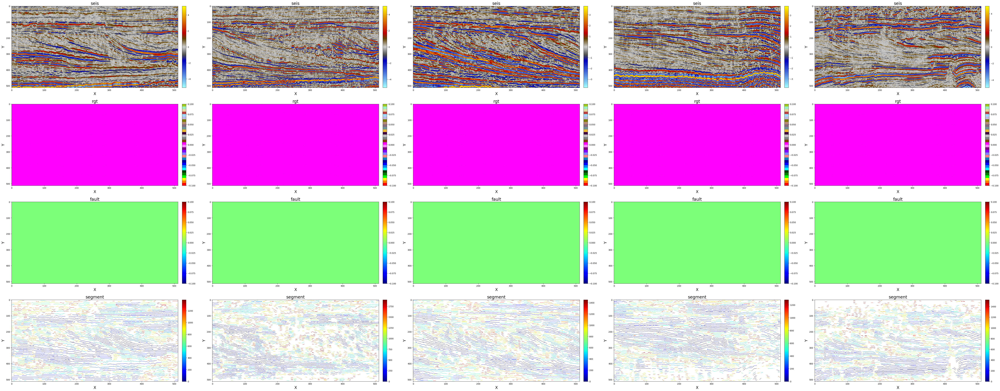

In [7]:
# plot
idxs = np.random.randint(0, len(train_data1), size=5) 
batch_samples = [train_data1[i] for i in idxs]
draw_attr_list = input_attr_list + rgt_attr_list + fault_attr_list + prior_attr_list1
draw.draw_samples(batch_samples, draw_attr_list, 
                  cmap=[utils.getPetrelColors(),utils.getStrataColors(),"jet",utils.setAlpha("jet",FillExceptMin=True)],
                  methods=["bilinear","bilinear","nearest","nearest"])

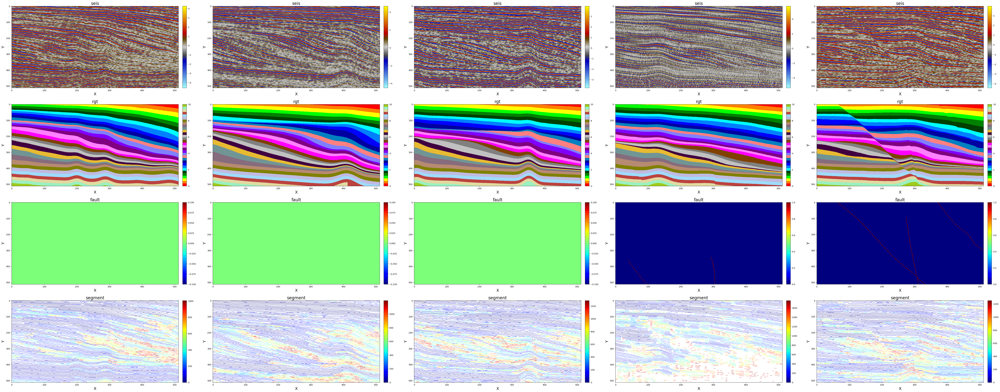

In [8]:
# plot
idxs = np.random.randint(0, len(train_data2), size=5) 
batch_samples = [train_data2[i] for i in idxs]
draw_attr_list = input_attr_list + rgt_attr_list + fault_attr_list + prior_attr_list1
draw.draw_samples(batch_samples, draw_attr_list, 
                  cmap=[utils.getPetrelColors(),utils.getStrataColors(),"jet",utils.setAlpha("jet",FillExceptMin=True)],
                  methods=["bilinear","bilinear","nearest","nearest"])

In [9]:
import SFM_pretrain.model_rgt as models_rgt
import loralib as lora

model = models_rgt.vit_base_patch16(img_size=512, in_chans=1, num_classes=1, drop_path_rate=0.1)
# state_dict = torch.load("./checkpoints/Pretrain_field2d_base/checkpoint-best.pth")['state_dict']
state_dict = torch.load("./checkpoints/Supervised_syn2d_base_step2_200epoch/checkpoint-best.pth")['state_dict']
new_state_dict = {k.replace('module.', ''): v for k, v in state_dict.items()} # 移除module.前缀
model.load_state_dict(new_state_dict)

utils.inject_lora_vit(model, r=8, alpha=16) # 插入lora,确保并行分支参数读入，而非随机参数
# lora.mark_only_lora_as_trainable(model)
for name, p in model.named_parameters():
#     if "lora_" in name or "decoder" in name or "segmentation_head" in name:
    if "lora_" in name:
        p.requires_grad = True
    else:
        p.requires_grad = False
        
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
trainable_params_ratio = trainable_params / total_params * 100
print(f"Total parameters: {total_params},\nTrainable parameters: {trainable_params},\nTrainable parameters ratio: {trainable_params_ratio:.2f}%")

# 并行模式
if torch.cuda.is_available():
    model = torch.nn.DataParallel(model, device_ids=range(num_GPU)).to(device)
else:
    model = model.to(device)
    
# 模型保存路径
checkpoint_path = os.path.join('checkpoints', Modelname)
if not os.path.exists(checkpoint_path):
    os.makedirs(checkpoint_path)
print(f"模型读取路径: {checkpoint_path}")

Total parameters: 89491362,
Trainable parameters: 442368,
Trainable parameters ratio: 0.49%
模型读取路径: checkpoints/RLHF_fieldsyn2d_base_step2_200epoch


In [10]:
# 定义训练参数
param = {}
param['epochs'] = 101     # 训练轮数
param['batch_size'] = 32   # 批大小
param['lr'] = 1e-3         # 学习率
# SGD
param['gamma'] = 0.9      # 学习率衰减系数
param['step_size'] = 50  # 学习率衰减间隔
param['momentum'] = 0.8    # 动量
# Adam
param['lr_factor'] = 0.5 # 学习因子
param['lr_patience'] = 2 # 容忍因子
param['weight_decay'] = 0 # 权重衰减(1e-4)

param['optimizer_type'] = 'Adam' # 优化器类型
param['checkpoint_path'] = checkpoint_path
param['disp_inter'] = 1 # 显示间隔
param['save_inter'] = 10 # 保存间隔

Epoch:0, FieldLoss:0.25502 <0.1247&0.1303>, SynLoss: 0.00619 <0.0006&0.0012&0.0027&0.0017>, Learning rate: 0.001000
Epoch:1, FieldLoss:0.25186 <0.1222&0.1297>, SynLoss: 0.00588 <0.0003&0.0012&0.0027&0.0017>, Learning rate: 0.001000
Epoch:2, FieldLoss:0.22831 <0.0985&0.1298>, SynLoss: 0.00585 <0.0003&0.0012&0.0027&0.0017>, Learning rate: 0.001000
Epoch:3, FieldLoss:0.21975 <0.0899&0.1299>, SynLoss: 0.00581 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.001000
Epoch:4, FieldLoss:0.21723 <0.0876&0.1297>, SynLoss: 0.00582 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.001000
Epoch:5, FieldLoss:0.20967 <0.0795&0.1302>, SynLoss: 0.00585 <0.0003&0.0012&0.0027&0.0017>, Learning rate: 0.001000
Epoch:6, FieldLoss:0.20614 <0.0768&0.1293>, SynLoss: 0.00598 <0.0003&0.0012&0.0027&0.0017>, Learning rate: 0.001000
Epoch:7, FieldLoss:0.22540 <0.0957&0.1297>, SynLoss: 0.00584 <0.0003&0.0012&0.0027&0.0017>, Learning rate: 0.001000
Epoch:8, FieldLoss:0.20579 <0.0761&0.1297>, SynLoss: 0.00583 <0.0003&0.0

Epoch:71, FieldLoss:0.15576 <0.0308&0.1249>, SynLoss: 0.00577 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000063
Epoch:72, FieldLoss:0.15648 <0.0316&0.1248>, SynLoss: 0.00579 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000063
Epoch:73, FieldLoss:0.15593 <0.0307&0.1252>, SynLoss: 0.00576 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000063
Epoch:74, FieldLoss:0.15620 <0.0310&0.1252>, SynLoss: 0.00575 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000063
Epoch:75, FieldLoss:0.15510 <0.0304&0.1247>, SynLoss: 0.00577 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000031
Epoch:76, FieldLoss:0.15568 <0.0308&0.1249>, SynLoss: 0.00575 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000031
Epoch:77, FieldLoss:0.15806 <0.0329&0.1252>, SynLoss: 0.00576 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000031
Epoch:78, FieldLoss:0.15713 <0.0321&0.1250>, SynLoss: 0.00577 <0.0003&0.0012&0.0026&0.0017>, Learning rate: 0.000031
Epoch:79, FieldLoss:0.15624 <0.0311&0.1251>, SynLoss: 0.00574 <0

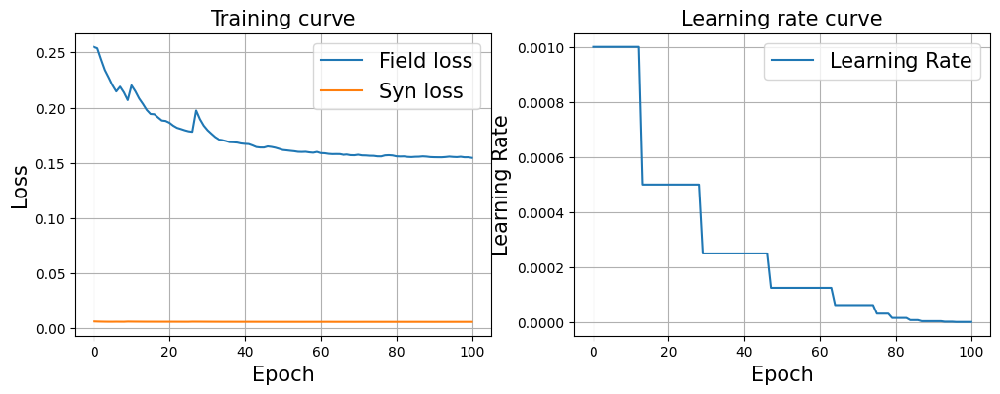

log has saved


In [11]:
model = utils.rl_train_stage3(param, model, train_data1, train_data2, input_attrs=["seis"],
                               prior_attrs1=["segment"],prior_attrs2=["normal"],
                               output_attrs=["rgt"],output_attrs2=["fault"],plot=True)

In [12]:
quit()